In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [5]:
df = pd.read_csv("Student_Performance.csv")
print(df.head())
print(df.info())
print(df.describe())
print("Missing values:\n", df.isnull().sum())

   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------              

In [7]:
df["Extracurricular Activities"] = df["Extracurricular Activities"].map({"Yes": 1, "No": 0})
display(df.head())

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


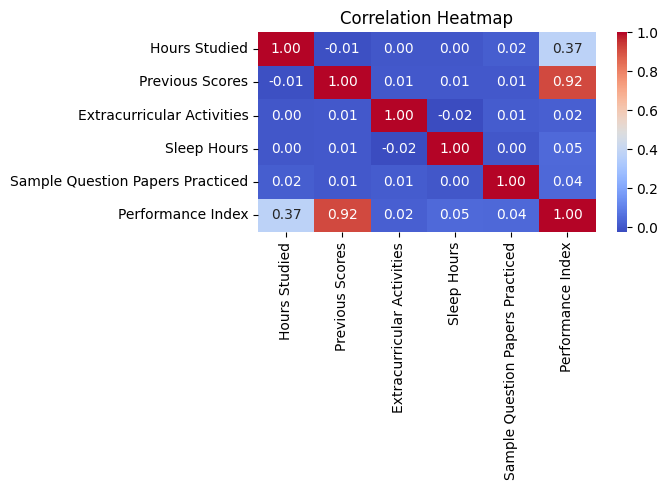

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("01_correlation.png")
plt.show()

In [10]:
X_simple = df[['Hours Studied']]
y = df["Performance Index"]

# Split the dataset into training and testing sets
X_simple_train, X_simple_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Initialize and train the simple linear regression model
simple_model = LinearRegression()
simple_model.fit(X_simple_train, y_train)

# Print model performance and parameters
print("=== SIMPLE LINEAR REGRESSION ===")
print("Intercept (b0):", simple_model.intercept_)
print("Slope (b1):", simple_model.coef_[0])

# Evaluate predictions
y_pred = simple_model.predict(X_simple_test)
print("R2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


=== SIMPLE LINEAR REGRESSION ===
Intercept (b0): 41.436634826535744
Slope (b1): 2.784300441170774
R2: 0.13160425385996788
RMSE: 17.93919001285204


In [11]:
# Define feature columns (X) and target (y)
X_multiple = df.drop(columns=['Performance Index'])
y = df['Performance Index']

# Split into train and test sets (80% train, 20% test)
X_mult_train, X_mult_test, y_train, y_test = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

# Initialize and train the multiple linear regression model
multiple_model = LinearRegression()
multiple_model.fit(X_mult_train, y_train)

# Evaluate predictions
y_pred_mult = multiple_model.predict(X_mult_test)

print("=== MULTIPLE LINEAR REGRESSION ===")
print("Intercept (b0):", multiple_model.intercept_)
for col, coef in zip(X_multiple.columns, multiple_model.coef_):
    print(f"{col} coefficient:", coef)

print("\nEvaluation Metrics:")
print("R2:", r2_score(y_test, y_pred_mult))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_mult)))


=== MULTIPLE LINEAR REGRESSION ===
Intercept (b0): -33.92194621555638
Hours Studied coefficient: 2.8524839300725775
Previous Scores coefficient: 1.016988198932932
Extracurricular Activities coefficient: 0.60861667957642
Sleep Hours coefficient: 0.4769414841762728
Sample Question Papers Practiced coefficient: 0.19183144145054246

Evaluation Metrics:
R2: 0.9889832909573145
RMSE: 2.0205515085050054


=== MULTICOLLINEARITY CHECK (VIF) ===
                            Feature       VIF
0                     Hours Studied  1.000478
1                   Previous Scores  1.000326
2        Extracurricular Activities  1.000802
3                       Sleep Hours  1.000600
4  Sample Question Papers Practiced  1.000557


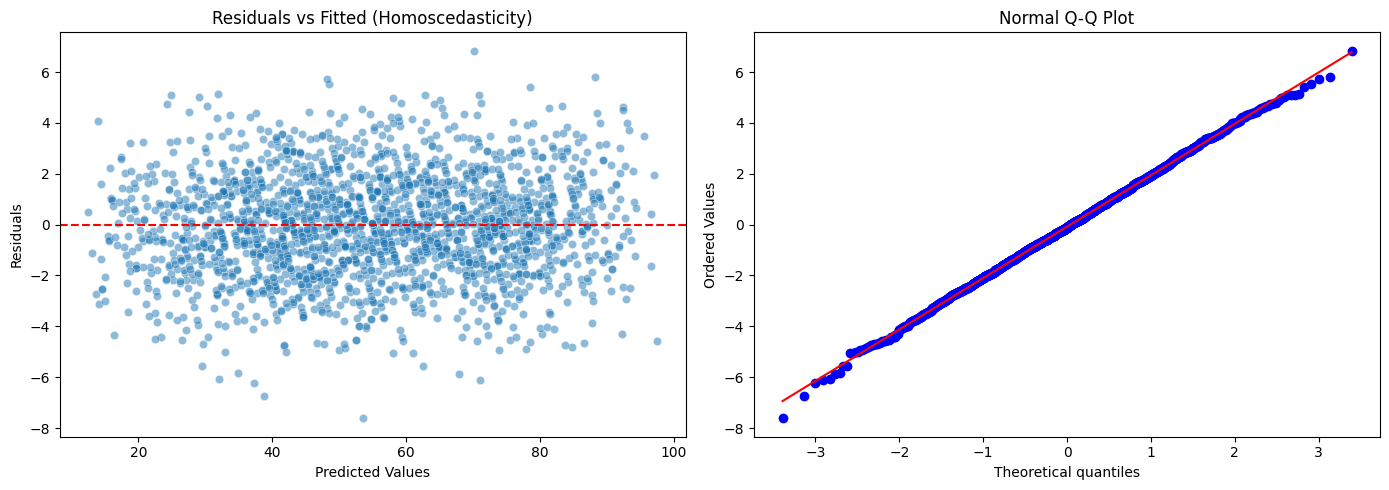

In [13]:
# 1. Calculate Variance Inflation Factor (VIF) to check for multicollinearity
print("=== MULTICOLLINEARITY CHECK (VIF) ===")
X_vif = df.drop(columns=['Performance Index'])
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]
print(vif_data)

# 2. Residual Diagnostics
residuals = y_test - y_pred_mult

# Create a plot with two subplots: Residuals vs Fitted & Normal Q-Q Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted Plot (Homoscedasticity check)
sns.scatterplot(x=y_pred_mult, y=residuals, ax=axes[0], alpha=0.5)
axes[0].axhline(y=0, color='r', linestyle='--')
axes[0].set_title("Residuals vs Fitted (Homoscedasticity)")
axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")

# Q-Q Plot (Normality of residuals check)
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.savefig("02_regression_diagnostics.png")
plt.show()


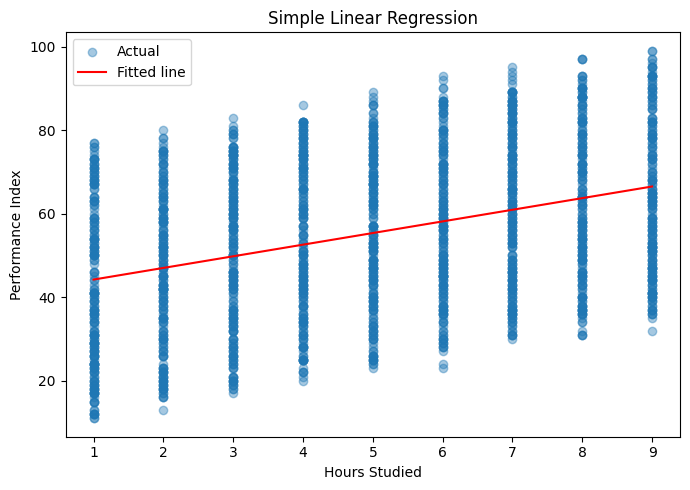

In [15]:
plt.figure(figsize=(7, 5))
plt.scatter(X_simple_test['Hours Studied'], y_test, alpha=0.4, label="Actual")

# Sort values for a smooth line plot
sorted_hours = X_simple_test['Hours Studied'].sort_values()
predicted_line = simple_model.predict(sorted_hours.to_frame())

plt.plot(sorted_hours, predicted_line, color="red", label="Fitted line")
plt.xlabel("Hours Studied")
plt.ylabel("Performance Index")
plt.legend()
plt.title("Simple Linear Regression")
plt.tight_layout()
plt.savefig("02_simple_fit.png")
plt.show()

In [22]:
X = df.drop(columns="Performance Index")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

print("\n--- MULTIPLE LINEAR REGRESSION ---")
print("Intercept: ", multi_model.intercept_)
for name, coef in zip(X.columns, multi_model.coef_):
    print(f"  {name:35s} {coef:.4f}")

y_pred = multi_model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print("R2: ", r2)
print("Adjusted R2: ", adj_r2)
print("RMSE: ", rmse)



--- MULTIPLE LINEAR REGRESSION ---
Intercept:  -33.92194621555638
  Hours Studied                       2.8525
  Previous Scores                     1.0170
  Extracurricular Activities          0.6086
  Sleep Hours                         0.4769
  Sample Question Papers Practiced    0.1918
R2:  0.9889832909573145
Adjusted R2:  0.9889556663107681
RMSE:  2.0205515085050054



                             OLS Regression Results                            
Dep. Variable:      Performance Index   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.398e+05
Date:                Mon, 02 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:51:49   Log-Likelihood:                -17063.
No. Observations:                8000   AIC:                         3.414e+04
Df Residuals:                    7994   BIC:                         3.418e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
const 

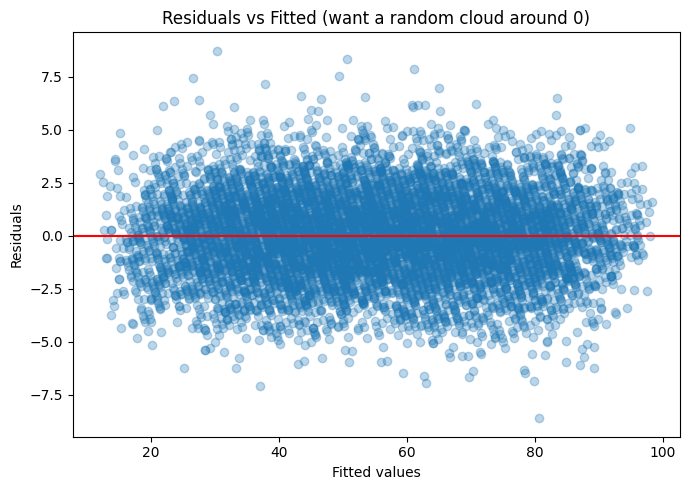

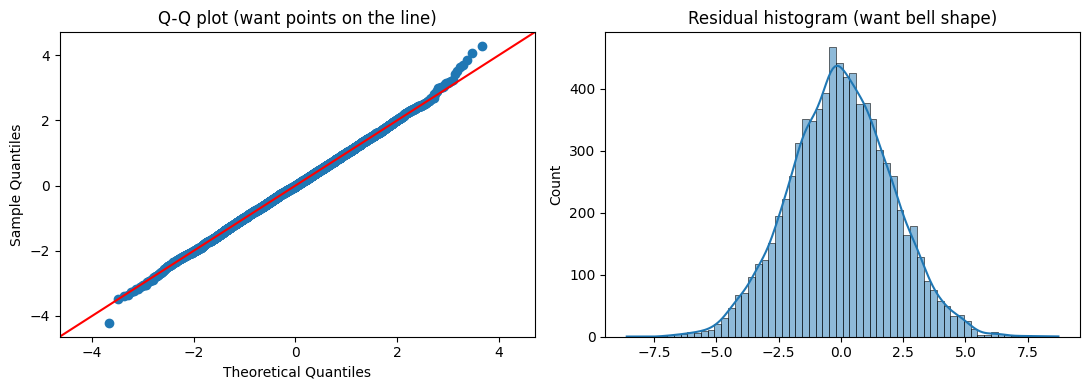

Breusch-Pagan p-value: 0.2396245087908097


In [23]:
# 5. CHECKING ASSUMPTIONS (ols statsmodels on the training data)
# -------------------------------------------------------------
X_train_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_sm).fit()
print("\n", ols.summary())

fitted = ols.fittedvalues
resid = ols.resid

# 5a. Linearity & Homoscedasticity: residuals vs fitted
plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.3)
plt.axhline(0, color="red")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (want a random cloud around 0)")
plt.tight_layout()
plt.savefig("5a_resid_vs_fitted.png")
plt.show()

# 5b. Normality of residuals: Q-Q plot + histogram
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sm.qqplot(resid, line='45', fit=True, ax=ax[0])
ax[0].set_title("Q-Q plot (want points on the line)")
sns.histplot(resid, kde=True, ax=ax[1])
ax[1].set_title("Residual histogram (want bell shape)")
plt.tight_layout()
plt.savefig("04_normality.png")
plt.show()

# 5c. Homoscedasticity test: Breusch-Pagan (p > 0.05 => constant variance OK)
bp_stat, bp_p, _, _ = het_breuschpagan(resid, X_train_sm)
print("Breusch-Pagan p-value:", bp_p)

Breusch-Pagan p-value: 0.2396245087908097
Durbin-Watson: 2.0331060225040156


,Feature,VIF
0,Hours Studied,1.000387
1,Previous Scores,1.000243
2,Extracurricular Activities,1.000428
3,Sleep Hours,1.000461
4,Sample Question Papers Practiced,1.000320



VIF
                             Feature       VIF
0                     Hours Studied  1.000387
1                   Previous Scores  1.000243
2        Extracurricular Activities  1.000428
3                       Sleep Hours  1.000461
4  Sample Question Papers Practiced  1.000320


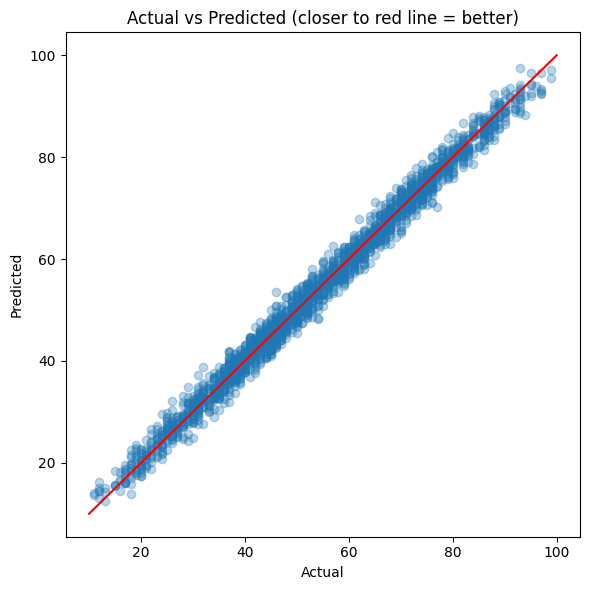

In [26]:
print("Breusch-Pagan p-value:", bp_p)

# 5d. Independence of errors: Durbin-Watson (~2 means no autocorrelation)
print("Durbin-Watson:", durbin_watson(resid))

# 5e. Multicollinearity: VIF (want < 5, worry above 10)
vif = pd.DataFrame()
vif["Feature"] = X_train.columns
vif["VIF"] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]
display(vif)
print(f"\nVIF\n", vif[vif["Feature"] != "const"])

# 6. FINAL: Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red")  # perfect predict
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted (closer to red line = better)")
plt.tight_layout()
plt.savefig("as_actual_vs_pred.png")
plt.show()